# PakWheels used car listings, September 2026

Listings scraped from PakWheels on a single day (28 Sep 2026): one row per advert, with make, model, variant, year, asking price, mileage, fuel, transmission, engine size and city.

Source: https://www.kaggle.com/datasets/danishjmeo/pakistan-used-cars-dataset-prices-and-specs-2026

Two things to keep in mind all the way through. These are asking prices typed in by sellers, not what the cars sold for. And it is a one-day snapshot, so anything about "age" compares different cars of different years, not the same car over time.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

charts = Path('charts')
charts.mkdir(exist_ok=True)

blue, orange, aqua, yellow, magenta, green = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
palette = [blue, orange, aqua, yellow, magenta, green]
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.edgecolor': '#c9c8c3', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=palette),
})

def save(name):
    plt.savefig(charts / f'{name}.png')
    plt.show()

## Loading and a first look

In [2]:
raw = pd.read_csv('pakwheels_used_cars_2026_clean.csv')
print(raw.shape)
raw.head()

(10589, 17)


,listing_id,title,brand,model,variant,year,price_pkr,price_outlier_flag,mileage_km,mileage_flag,fuel_type,transmission,engine_cc,engine_cc_flag,city,link,scraped_at
0,1,Toyota Prado 3rd (J120) Generation 2003 TZ 3.4...,Toyota,Prado,3rd (J120) Generation TZ 3.4,2003,6800000,False,"161,969.00",NaN,Petrol,Automatic,"3,400.00",NaN,Lahore,https://www.pakwheels.com/used-cars/toyota-pra...,2026-09-28
1,2,Changan Alsvin 2022 1.3L MT Comfort for Sale,Changan,Alsvin,1.3L MT Comfort,2022,3050000,False,"59,216.00",NaN,Petrol,Manual,"1,300.00",NaN,Lahore,https://www.pakwheels.com/used-cars/changan-al...,2026-09-28
2,3,Suzuki Cultus 2022 VXL for Sale,Suzuki,Cultus,VXL,2022,3400000,False,"22,120.00",NaN,Petrol,Manual,"1,000.00",NaN,Karachi,https://www.pakwheels.com/used-cars/suzuki-cul...,2026-09-28
3,4,Honda City 6th (GM4) Generation 2025 1.5L ASPI...,Honda,City,6th (GM4) Generation 1.5L ASPIRE CVT,2025,6100000,False,"14,339.00",NaN,Petrol,Automatic,"1,500.00",NaN,Rawalpindi,https://www.pakwheels.com/used-cars/honda-city...,2026-09-28
4,5,Hyundai Santa Fe 2026 Signature for Sale,Hyundai,Santa,Fe Signature,2026,14500000,True,10.00,NaN,Hybrid,Automatic,"1,600.00",NaN,Karachi,https://www.pakwheels.com/used-cars/hyundai-sa...,2026-09-28


In [3]:
info = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'unique': raw.nunique()})
info

,dtype,missing,unique
listing_id,int64,0,10589
title,str,0,3630
brand,str,0,60
model,str,0,297
variant,str,548,1003
year,int64,0,53
price_pkr,int64,0,1458
price_outlier_flag,bool,0,2
mileage_km,float64,95,3219
mileage_flag,str,10494,1


In [4]:
raw[['year', 'price_pkr', 'mileage_km', 'engine_cc']].describe().T

,count,mean,std,min,25%,50%,75%,max
year,"10,589.00","2,014.98",8.15,"1,961.00","2,010.00","2,017.00","2,021.00","2,026.00"
price_pkr,"10,589.00","4,927,348.64","6,268,950.55","150,000.00","2,175,000.00","3,429,999.00","5,500,000.00","108,000,000.00"
mileage_km,"10,494.00","99,448.58","82,339.44",6.00,"47,000.00","88,843.00","134,000.00","999,995.00"
engine_cc,"10,487.00","1,427.98",682.76,100.00,"1,000.00","1,300.00","1,600.00","5,700.00"


The file already has three flag columns from whoever prepared it, so worth seeing what they actually mean before trusting them.

In [5]:
print(raw.groupby('price_outlier_flag')['price_pkr'].agg(['count', 'min', 'max']))
print()
print(raw['mileage_flag'].value_counts(dropna=False))
print('mileage missing where flagged:', raw.loc[raw['mileage_flag'].notna(), 'mileage_km'].isna().all())
print()
print(raw['engine_cc_flag'].value_counts(dropna=False))
print('engine missing where flagged:', raw.loc[raw['engine_cc_flag'].notna(), 'engine_cc'].isna().all())
print()
print(raw['scraped_at'].unique())

                    count       min        max
price_outlier_flag                            
False                9815    150000   10400000
True                  774  10500000  108000000

mileage_flag
NaN                10494
implausible_low       95
Name: count, dtype: int64
mileage missing where flagged: True

engine_cc_flag
NaN                  10579
implausible_value       10
Name: count, dtype: int64
engine missing where flagged: True

<StringArray>
['2026-09-28']
Length: 1, dtype: str


So `price_outlier_flag` is just a cutoff: everything from 10.5 million PKR up is flagged (774 rows), which looks like an IQR fence. Those are Land Cruisers, Prados, Fortuners and new SUVs, not mistakes, so I keep them. The mileage and engine flags mark values the uploader already blanked out (95 and 10 rows). `scraped_at` is one date for every row.

## Checking how clean "clean" is

In [6]:
print('exact duplicate rows:', raw.duplicated().sum())
print('duplicate links:', raw['link'].duplicated().sum())
print('duplicate advert ids in link:', raw['link'].str.extract(r'-(\d+)$')[0].duplicated().sum())
same_car = ['title', 'year', 'price_pkr', 'mileage_km', 'city', 'fuel_type', 'transmission', 'engine_cc']
print('same car listed twice (all specs equal):', raw.duplicated(same_car).sum())

exact duplicate rows: 0
duplicate links: 0
duplicate advert ids in link: 0
same car listed twice (all specs equal): 0


In [7]:
# spellings that only differ by case or stray spaces
for col in ['brand', 'model', 'variant', 'city']:
    s = raw[col].dropna()
    groups = s.groupby(s.str.strip().str.lower()).unique()
    clash = groups[groups.str.len() > 1]
    print(col, '-', s.nunique(), 'values,', len(clash), 'case clashes', list(clash.values))

brand - 60 values, 0 case clashes []
model - 297 values, 1 case clashes [<StringArray>
['Ek', 'eK', 'EK']
Length: 3, dtype: str]
variant - 1003 values, 2 case clashes [<StringArray>
['Custom', 'CUSTOM']
Length: 2, dtype: str, <StringArray>
['EURO II', 'Euro II']
Length: 2, dtype: str]


city - 193 values, 0 case clashes []


In [8]:
# cities that look like the same place under two names
cities = raw['city'].value_counts()
print(cities[cities.index.str.contains('Dgkhan|Dera Ghazi|Swat|Mingora|Muzaffar G|Mian Wali|Nowshera|Shorkot|Sohawa')])

city
Dgkhan                   12
Nowshera                 10
Mian Wali                 7
Nowshera Cantt            7
Swat                      5
Muzaffar Gargh            4
Dera Ghazi Khan           4
Shorkot                   3
Swatmingora               2
Mingora                   1
Sohawa                    1
Shorkot Cantt             1
Sohawa District Daska     1
Name: count, dtype: int64


In [9]:
print(raw['fuel_type'].value_counts(dropna=False))
print()
print(raw.loc[raw['fuel_type'].isna(), 'title'].value_counts())

fuel_type
Petrol      9149
Hybrid       838
Diesel       316
PHEV         109
Electric      92
CNG           59
LPG           16
NaN           10
Name: count, dtype: int64

title
Deepal S05 2026 REEV Premium for Sale    6
Deepal S05 2026 for Sale                 2
Jetour T2 2026 PHEV for Sale             1
MG HS 2025 PHEV for Sale                 1
Name: count, dtype: int64


No duplicates of any kind, which is good. Text is nearly consistent: one model written three ways (Ek / eK / EK), two variant case clashes, and a few city aliases (Dgkhan and Dera Ghazi Khan, Swatmingora and Mingora). The ten rows with no fuel type are all plug-in or range-extender cars, readable from the title.

Now the numbers. Prices first: compare each advert with the median for the same model and year.

In [10]:
grp = raw.groupby(['model', 'year'])['price_pkr']
check = raw.assign(peer_median=grp.transform('median'), peers=grp.transform('size'))
check['ratio'] = check['price_pkr'] / check['peer_median']
bad_price = check[(check['peers'] >= 5) & ((check['ratio'] > 3) | (check['ratio'] < 1/3))]
bad_price[['title', 'city', 'price_pkr', 'peer_median', 'peers', 'ratio', 'mileage_km']]

,title,city,price_pkr,peer_median,peers,ratio,mileage_km
70,Toyota Corolla 2013 GLi 1.3 VVTi for Sale,Mirpur Ak,330000,"3,050,000.00",60,0.11,160.00
345,Honda Civic 2004 for Sale,Lahore,183000,"1,680,000.00",27,0.11,"188,680.00"
6646,MG ZS 2026 Hybrid+ Essence for Sale,Lahore,82000000,"8,287,500.00",10,9.89,12.00


Three adverts are way off their peers: an MG ZS at 82 million (about ten times the others, almost certainly an extra zero) and a 2013 Corolla and 2004 Civic at roughly a tenth of the going rate (a down payment or a missing digit). I drop these three. Everything else sits within 3x of its model-year median.

In [11]:
m = raw['mileage_km']
age = (2026 - raw['year']).clip(lower=1)
print('mileage >= 500,000 km:', (m >= 500000).sum())
print('more than 60,000 km per year of age:', ((m / age > 60000) & (m < 500000)).sum())
print('under 1,000 km on a 2023 or older car:', ((m < 1000) & (raw['year'] <= 2023)).sum())
print('under 1,000 km on a 2024-2026 car:', ((m < 1000) & (raw['year'] >= 2024)).sum())
print('share of mileages that are a round thousand:', round((m.dropna() % 1000 == 0).mean(), 3))
print()
print(raw.loc[m >= 900000, ['title', 'mileage_km']].sort_values('mileage_km', ascending=False).head(8).to_string(index=False))
print()
print(raw.loc[(m < 1000) & (raw['year'] <= 2023), 'mileage_km'].value_counts().head(6))

mileage >= 500,000 km: 60
more than 60,000 km per year of age: 16
under 1,000 km on a 2023 or older car: 122
under 1,000 km on a 2024-2026 car: 161
share of mileages that are a round thousand: 0.674

                                           title  mileage_km
                    Suzuki Potohar 1986 for Sale  999,995.00
                  Suzuki Cultus 2006 VX for Sale  999,949.00
                      Toyota Platz 2002 for Sale  999,000.00
                      Suzuki FX 1984 GA for Sale  998,855.00
Honda Civic 5th (EG) Generation 1995 EX for Sale  995,000.00
                 Suzuki Cultus 2005 VXR for Sale  990,000.00
                Suzuki Cultus 2007 VXRi for Sale  990,000.00
            Honda City 1998 EXi Neo 1.5 for Sale  989,898.00

mileage_km
123.00    10
100.00     8
150.00     6
786.00     5
170.00     5
130.00     3
Name: count, dtype: int64


Mileage is the weak column. About two thirds of the values are round thousands, so they are estimates. There is a tail of filler values at the top (999,995, 989,898, 545,454, an 800,000 km 2024 Wagon R) and at the bottom (123, 786 and 100 km on twenty-year-old cars). The uploader blanked 95 low ones but left these. I blank the ones that are not believable: 500,000 km or more, more than 60,000 km per year of age, or under 1,000 km on a car from 2023 or earlier. Low mileage on 2024-2026 cars is left alone, those are mostly unregistered new cars being resold.

In [12]:
print(raw.loc[raw['engine_cc'] < 650, ['title', 'fuel_type', 'engine_cc']].to_string(index=False))
print()
print('electric cars with an engine size:', raw.loc[raw['fuel_type'] == 'Electric', 'engine_cc'].notna().sum(), 'of', (raw['fuel_type'] == 'Electric').sum())
print()
old = raw[raw['year'] < 1980]
print(old[['title', 'year', 'price_pkr']].to_string(index=False))

                      title fuel_type  engine_cc
   Honda City 2007 for Sale    Petrol     100.00
Suzuki Mehran 2005 for Sale    Petrol     250.00
   Willys M38 2023 for Sale    Petrol     250.00
Daihatsu Move 2014 for Sale    Petrol     600.00
Suzuki Cultus 2010 for Sale    Petrol     100.00
Suzuki Mehran 2016 for Sale    Petrol     600.00

electric cars with an engine size: 0 of 92

                              title  year  price_pkr
       Toyota Corolla 1976 for Sale  1976    1250000
Mercedes Benz X Class 1966 for Sale  1966    4700000
         Nissan Sunny 1979 for Sale  1979     350000
       Toyota Corolla 1973 for Sale  1973     350000
           Willys M38 1961 for Sale  1961    1600000
          Nissan 350Z 1973 for Sale  1973     350000
      Nissan Wingroad 1961 for Sale  1961    1500000
        Toyota Celica 1973 for Sale  1973    2500000
            Willys MB 1978 for Sale  1978    2050000


Six petrol cars have an engine under 650 cc that cannot be right (a 100 cc Honda City). Electric cars have no engine size, which is correct rather than missing.

Years run 1961 to 2026 and none is impossible as a number, but a few do not match the car: a "1973 Nissan 350Z", a "1961 Nissan Wingroad", a "2023 Willys M38", a "1966 Mercedes X Class". The year is whatever the seller picked. I cannot verify model against year for the whole file, so these stay in and get mentioned as a caveat.

## Cleaning

In [13]:
df = raw.copy()

# text: trim, and settle the few spellings that differ
for col in ['title', 'brand', 'model', 'variant', 'city', 'fuel_type', 'transmission']:
    df[col] = df[col].str.strip()
df['model'] = df['model'].replace({'eK': 'Ek', 'EK': 'Ek'})
df['variant'] = df['variant'].replace({'CUSTOM': 'Custom', 'EURO II': 'Euro II'})
df['city'] = df['city'].replace({'Dgkhan': 'Dera Ghazi Khan', 'Swatmingora': 'Mingora',
                                 'Muzaffar Gargh': 'Muzaffargarh', 'Mian Wali': 'Mianwali'})

# fuel type is in the title for the 10 blanks
no_fuel = df['fuel_type'].isna()
df.loc[no_fuel & df['title'].str.contains('PHEV'), 'fuel_type'] = 'PHEV'
df.loc[no_fuel & df['title'].str.contains('Deepal S05'), 'fuel_type'] = 'REEV'

# the three prices that are an order of magnitude off
df = df.drop(index=bad_price.index)

# mileage that cannot be believed -> missing, and say why in the existing flag column
m = df['mileage_km']
age = (2026 - df['year']).clip(lower=1)
too_high = (m >= 500000) | (m / age > 60000)
too_low = (m < 1000) & (df['year'] <= 2023)
df.loc[too_high, 'mileage_flag'] = 'implausible_high'
df.loc[too_low, 'mileage_flag'] = 'implausible_low'
df.loc[too_high | too_low, 'mileage_km'] = np.nan

tiny_engine = df['engine_cc'] < 650
df.loc[tiny_engine, 'engine_cc_flag'] = 'implausible_value'
df.loc[tiny_engine, 'engine_cc'] = np.nan

df['scraped_at'] = pd.to_datetime(df['scraped_at'])
df['age_years'] = 2026 - df['year']
df['price_million'] = df['price_pkr'] / 1e6
df = df.reset_index(drop=True)

print('rows:', len(raw), '->', len(df))
print('mileage blanked: high', too_high.sum(), '| low', too_low.sum())
print('engine sizes blanked:', tiny_engine.sum())
print('fuel types filled:', no_fuel.sum())
print('cities:', raw['city'].nunique(), '->', df['city'].nunique(), '| models:', raw['model'].nunique(), '->', df['model'].nunique())
print()
print(df[['variant', 'mileage_km', 'fuel_type', 'engine_cc']].isna().sum())

rows: 10589 -> 10586
mileage blanked: high 76 | low 121
engine sizes blanked: 6
fuel types filled: 10
cities: 193 -> 191 | models: 297 -> 295

variant       547
mileage_km    292
fuel_type       0
engine_cc     108
dtype: int64


What is left missing: variant on about 5% of adverts (the seller did not pick one), mileage where it was blanked, and engine size for electric cars plus a few blanks. I do not fill any of these in; medians below just skip them.

In [14]:
df.drop(columns='price_million').to_csv('used_cars_cleaned.csv', index=False)
print(df.shape)

(10586, 19)


## What is in the listings

In [15]:
print('listings:', len(df), '| makes:', df['brand'].nunique(), '| models:', df['model'].nunique(), '| cities:', df['city'].nunique())
print()
print(df[['price_pkr', 'year', 'age_years', 'mileage_km', 'engine_cc']].describe(percentiles=[.1, .25, .5, .75, .9]).T)

listings: 10586 | makes: 60 | models: 295 | cities: 191



               count         mean          std        min          10%          25%          50%          75%          90%            max
price_pkr  10,586.00 4,920,950.48 6,224,590.38 150,000.00 1,120,000.00 2,180,000.00 3,432,499.50 5,500,000.00 8,700,000.00 108,000,000.00
year       10,586.00     2,014.98         8.15   1,961.00     2,005.00     2,010.00     2,017.00     2,021.00     2,024.00       2,026.00
age_years  10,586.00        11.02         8.15       0.00         2.00         5.00         9.00        16.00        21.00          65.00
mileage_km 10,294.00    97,036.08    66,935.38      10.00    19,000.00    48,650.00    89,000.00   133,000.00   184,294.00     491,000.00
engine_cc  10,478.00     1,428.63       682.52     658.00       660.00     1,000.00     1,300.00     1,600.00     2,000.00       5,700.00

In [16]:
top_brands = df['brand'].value_counts()
print((top_brands.head(10) / len(df) * 100).round(1))
print('top 3 makes share: %.1f%%' % (top_brands.head(3).sum() / len(df) * 100))
print()
top_cities = df['city'].value_counts()
print((top_cities.head(8) / len(df) * 100).round(1))
print('top 3 cities share: %.1f%%' % (top_cities.head(3).sum() / len(df) * 100))
print('cities with fewer than 10 listings:', (top_cities < 10).sum(), 'of', len(top_cities))

brand
Toyota     29.40
Suzuki     24.60
Honda      20.70
Daihatsu    4.00
KIA         3.90
Hyundai     3.10
Nissan      2.50
Haval       1.50
Changan     1.50
MG          1.20
Name: count, dtype: float64
top 3 makes share: 74.7%

city
Lahore       28.20
Karachi      20.10
Islamabad    17.90
Rawalpindi    7.10
Faisalabad    3.70
Multan        3.00
Peshawar      3.00
Gujranwala    2.30
Name: count, dtype: float64
top 3 cities share: 66.3%
cities with fewer than 10 listings: 145 of 191


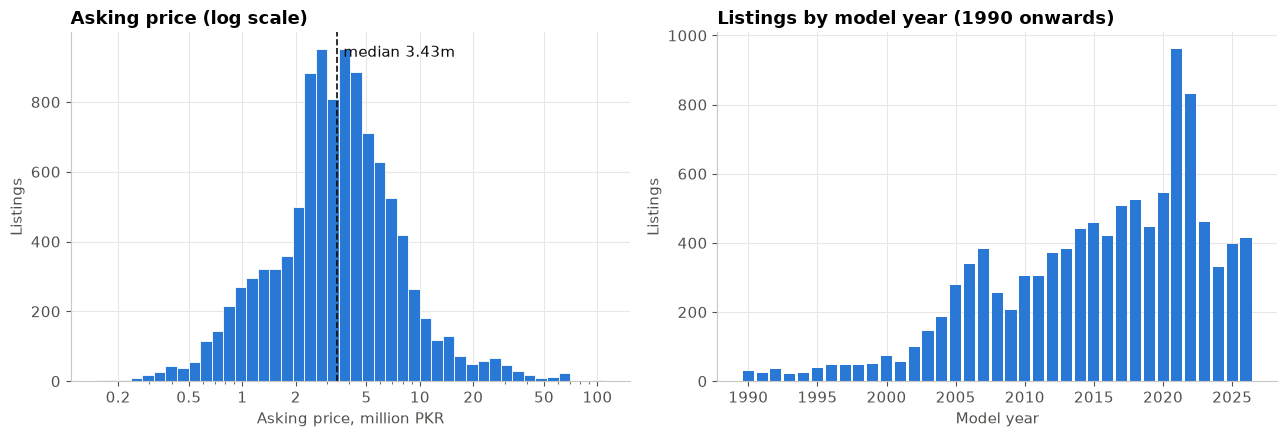

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.logspace(np.log10(0.15), np.log10(110), 45)
axes[0].hist(df['price_million'], bins=bins, color=blue, edgecolor='white', linewidth=0.6)
axes[0].set_xscale('log')
axes[0].set_xticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
axes[0].xaxis.set_major_formatter(mtick.FormatStrFormatter('%g'))
med = df['price_million'].median()
axes[0].axvline(med, color='#0b0b0b', linewidth=1.2, linestyle='--')
axes[0].text(med * 1.08, axes[0].get_ylim()[1] * 0.93, f'median {med:.2f}m', color='#0b0b0b')
axes[0].set_title('Asking price (log scale)')
axes[0].set_xlabel('Asking price, million PKR')
axes[0].set_ylabel('Listings')

by_year = df[df['year'] >= 1990]['year'].value_counts().sort_index()
axes[1].bar(by_year.index, by_year.values, color=blue, width=0.8)
axes[1].set_title('Listings by model year (1990 onwards)')
axes[1].set_xlabel('Model year')
axes[1].set_ylabel('Listings')
plt.tight_layout()
save('01_price_and_year_distribution')

Prices are heavily right-skewed, so medians and a log axis from here on. Half the adverts sit between roughly 2.2 and 5.5 million PKR. The year chart has a clear bump at 2021-2022 and another small one at 2006-2007, with a dip in 2023-2024.

## Price by make and model

Rankings only include makes and models with at least 30 listings, and cities with at least 50. Below that a median is two or three adverts talking.

In [18]:
MIN_MAKE, MIN_MODEL, MIN_CITY = 30, 30, 50

by_make = df.groupby('brand').agg(listings=('price_pkr', 'size'), median_price=('price_million', 'median'),
                                  p25=('price_million', lambda s: s.quantile(.25)), p75=('price_million', lambda s: s.quantile(.75)),
                                  median_year=('year', 'median'))
by_make = by_make[by_make['listings'] >= MIN_MAKE].sort_values('median_price', ascending=False)
print(len(by_make), 'makes with at least', MIN_MAKE, 'listings')
by_make

19 makes with at least 30 listings


,listings,median_price,p25,p75,median_year
brand,,,,,
Tank,30,22.40,21.10,23.38,"2,026.00"
Audi,56,12.00,8.65,15.80,"2,018.00"
Haval,164,9.32,8.57,10.20,"2,025.00"
BYD,31,9.15,8.05,19.60,"2,026.00"
Mercedes Benz,127,8.50,5.10,13.50,"2,011.00"
Jaecoo,40,8.45,7.99,9.93,"2,026.00"
BMW,30,7.22,4.43,20.88,"2,011.50"
Hyundai,332,7.00,5.14,8.50,"2,022.00"
MG,128,6.40,5.70,8.20,"2,022.50"


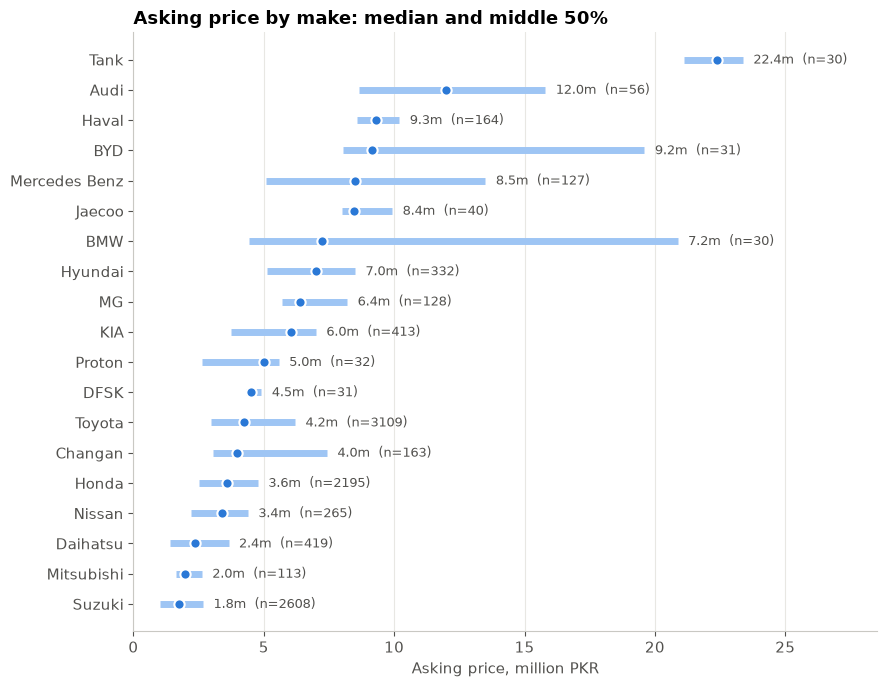

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))
d = by_make.sort_values('median_price')
ax.hlines(d.index, d['p25'], d['p75'], color='#9ec5f4', linewidth=5)
ax.scatter(d['median_price'], d.index, color=blue, s=55, zorder=3, edgecolor='white', linewidth=1.5)
for name, row in d.iterrows():
    ax.text(row['p75'] + 0.4, name, f"{row['median_price']:.1f}m  (n={int(row['listings'])})", va='center', fontsize=9, color='#52514e')
ax.set_xlim(0, d['p75'].max() * 1.22)
ax.set_title('Asking price by make: median and middle 50%')
ax.set_xlabel('Asking price, million PKR')
ax.grid(axis='y', visible=False)
plt.tight_layout()
save('02_price_by_make')

The newer Chinese and plug-in brands (Tank, BYD, Jaecoo, Haval) sit at the top mostly because nearly all their stock is one or two years old, see the median year column. Suzuki and Daihatsu are at the bottom with small cars and a lot of old stock. So this ranks what is on sale, not which make holds value.

In [20]:
by_model = df.groupby(['brand', 'model']).agg(listings=('price_pkr', 'size'), median_price=('price_million', 'median'),
                                              median_year=('year', 'median'), median_km=('mileage_km', 'median'))
by_model = by_model[by_model['listings'] >= MIN_MODEL]
print(len(by_model), 'models with at least', MIN_MODEL, 'listings')
print()
print('most listed')
print(by_model.sort_values('listings', ascending=False).head(12))
print()
print('highest median asking price')
print(by_model.sort_values('median_price', ascending=False).head(10))
print()
print('lowest median asking price')
print(by_model.sort_values('median_price').head(10))

54 models with at least 30 listings

most listed
                 listings  median_price  median_year  median_km
brand  model                                                   
Toyota Corolla       1241          3.67     2,015.00 113,000.00
Honda  Civic          960          3.50     2,014.00 112,672.50
       City           831          3.40     2,016.00 104,750.00
Suzuki Cultus         538          1.53     2,013.00  89,896.00
       Mehran         501          0.93     2,010.00  80,000.00
       Alto           495          2.51     2,020.00  70,000.00
       Wagon R        327          2.55     2,019.00  90,000.00
       Swift          252          2.60     2,017.00  87,205.50
Toyota Vitz           251          2.65     2,011.00 125,000.00
       Yaris          244          4.45     2,021.00  60,956.00
KIA    Sportage       221          6.50     2,021.00  58,000.00
Toyota Prado          190         16.25     2,013.00  85,000.00

highest median asking price
                          

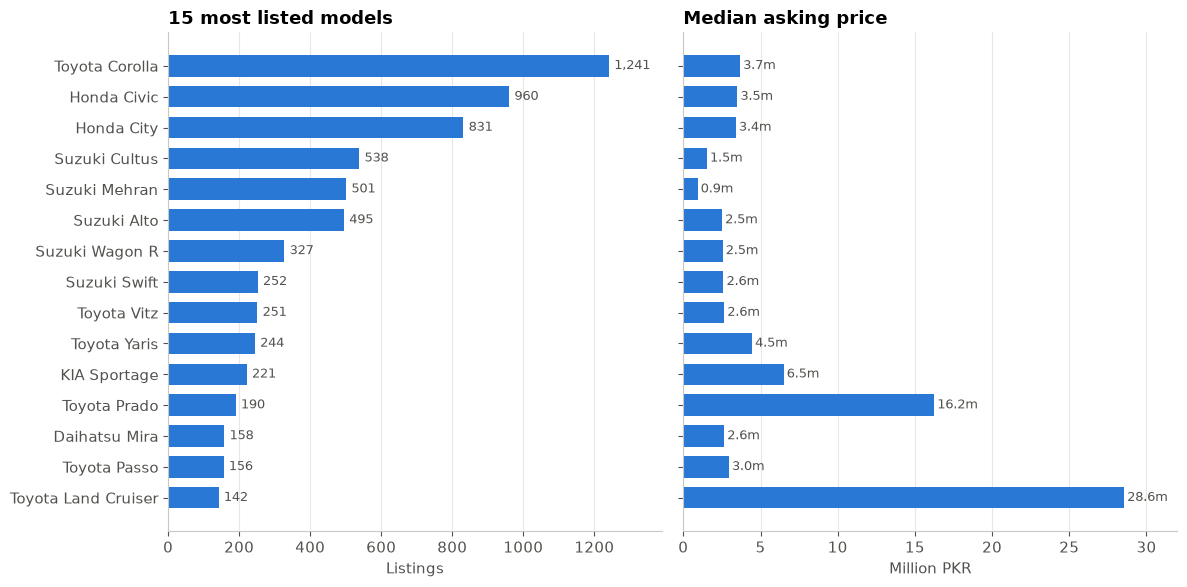

In [21]:
top15 = by_model.sort_values('listings', ascending=False).head(15).reset_index()
top15['label'] = top15['brand'] + ' ' + top15['model']
top15 = top15.sort_values('listings')

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axes[0].barh(top15['label'], top15['listings'], color=blue, height=0.7)
for y, v in zip(top15['label'], top15['listings']):
    axes[0].text(v + 15, y, f'{v:,}', va='center', fontsize=9, color='#52514e')
axes[0].set_title('15 most listed models')
axes[0].set_xlabel('Listings')
axes[0].set_xlim(0, top15['listings'].max() * 1.12)

axes[1].barh(top15['label'], top15['median_price'], color=blue, height=0.7)
for y, v in zip(top15['label'], top15['median_price']):
    axes[1].text(v + 0.2, y, f'{v:.1f}m', va='center', fontsize=9, color='#52514e')
axes[1].set_title('Median asking price')
axes[1].set_xlabel('Million PKR')
axes[1].set_xlim(0, top15['median_price'].max() * 1.12)
for ax in axes:
    ax.grid(axis='y', visible=False)
plt.tight_layout()
save('03_top_models')

## Price against age

This is a cross-section: a 2015 Corolla and a 2025 Corolla are different generations with different new prices. So the curves below show how asking prices step down by model year today, which is close to but not the same thing as depreciation.

In [22]:
by_age = df.groupby('age_years').agg(listings=('price_pkr', 'size'), median_price=('price_million', 'median'))
print(by_age.loc[[0, 1, 2, 3, 5, 8, 10, 15, 20, 25, 30]])
print()
print('Spearman correlation with price')
print(df[['price_pkr', 'year', 'mileage_km', 'engine_cc']].corr(method='spearman')['price_pkr'].round(3))

           listings  median_price
age_years                        
0               414          8.91
1               397          8.05
2               329          7.15
3               460          5.20
5               961          5.24
8               525          3.95
10              420          3.50
15              305          2.54
20              339          1.75
25               55          1.23
30               48          1.00

Spearman correlation with price
price_pkr     1.00
year          0.68
mileage_km   -0.42
engine_cc     0.62
Name: price_pkr, dtype: float64


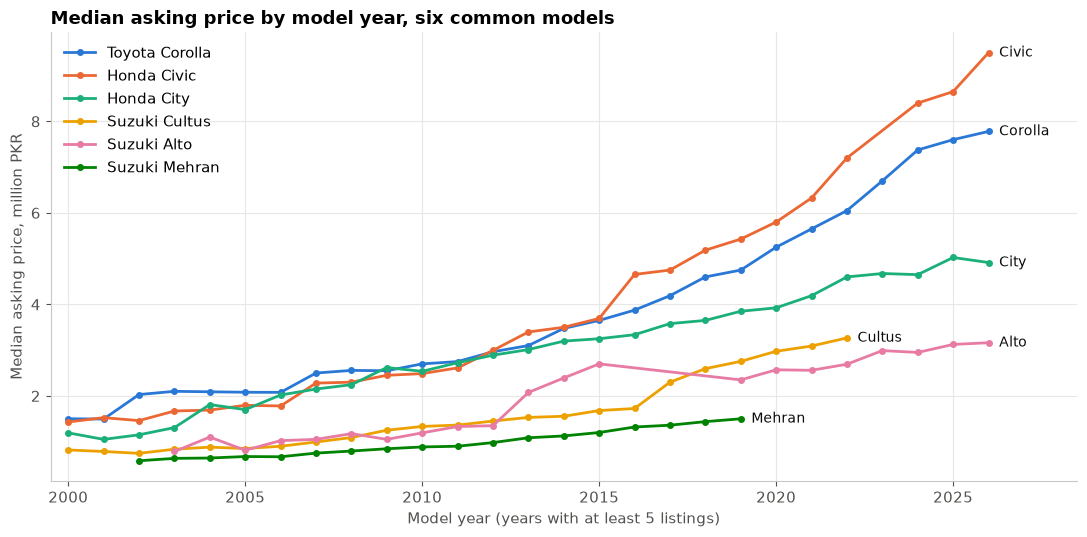

In [23]:
focus = [('Toyota', 'Corolla'), ('Honda', 'Civic'), ('Honda', 'City'), ('Suzuki', 'Cultus'), ('Suzuki', 'Alto'), ('Suzuki', 'Mehran')]

fig, ax = plt.subplots(figsize=(11, 5.5))
for (brand, model), col in zip(focus, palette):
    d = df[(df['brand'] == brand) & (df['model'] == model) & (df['year'] >= 2000)]
    g = d.groupby('year')['price_million'].agg(['median', 'size'])
    g = g[g['size'] >= 5]
    ax.plot(g.index, g['median'], marker='o', markersize=4, linewidth=2, color=col, label=f'{brand} {model}')
    ax.text(g.index[-1] + 0.3, g['median'].iloc[-1], model, va='center', fontsize=10, color='#0b0b0b')
ax.set_xlim(1999.5, 2028.5)
ax.set_title('Median asking price by model year, six common models')
ax.set_xlabel('Model year (years with at least 5 listings)')
ax.set_ylabel('Median asking price, million PKR')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
save('04_price_by_model_year')

In [24]:
# rough yearly step-down per model: slope of log(price) on age, cars up to 15 years old
rows = []
for (brand, model), d in df[df['age_years'] <= 15].groupby(['brand', 'model']):
    if len(d) < 100:
        continue
    slope = np.polyfit(d['age_years'], np.log(d['price_pkr']), 1)[0]
    new = d.loc[d['age_years'] <= 1, 'price_million']
    old = d.loc[d['age_years'].between(9, 11), 'price_million']
    rows.append({'model': f'{brand} {model}', 'listings_0_15y': len(d), 'pct_per_year': (np.exp(slope) - 1) * 100,
                 'median_0_1y': new.median() if len(new) >= 5 else np.nan, 'median_9_11y': old.median() if len(old) >= 5 else np.nan})
step = pd.DataFrame(rows).set_index('model').sort_values('pct_per_year')
step['ten_year_ratio'] = step['median_9_11y'] / step['median_0_1y']
step

,listings_0_15y,pct_per_year,median_0_1y,median_9_11y,ten_year_ratio
model,,,,,
MG HS,113,-9.95,8.85,NaN,NaN
Hyundai Tucson,119,-9.48,11.45,NaN,NaN
Suzuki Cultus,310,-8.72,NaN,1.80,NaN
Honda Vezel,102,-8.55,NaN,4.95,NaN
Honda Civic,614,-8.04,8.99,4.58,0.51
KIA Sportage,216,-7.90,10.80,NaN,NaN
Toyota Fortuner,111,-7.41,15.50,10.20,0.66
Toyota Corolla,894,-6.80,7.60,3.88,0.51
Suzuki Swift,238,-6.39,4.84,2.42,0.50


Across the models with 100 or more listings up to 15 years old, the asking price falls by between 2 and 10 percent for each extra year of age, and for most of them between 4 and 9. `ten_year_ratio` is the median for roughly ten-year-old cars divided by the median for cars up to a year old (blank where either end has fewer than 5 adverts). Old Suzukis do not get cheap in the way you might expect: the newest Mehrans in the data are 2019 models, and the median Mehran still asks close to a million.

## Mileage

To see mileage on its own I compare each car with the median for the same model and year (only where that group has 5 or more adverts), then look at that ratio across mileage bands. I average the ratio (geometric mean) rather than take its median, because so many prices are round numbers that the median ratio lands on exactly 1.00 for most groups.

In [25]:
grp = df.groupby(['model', 'year'])['price_pkr']
geo_mean = lambda s: np.exp(np.log(s).mean())
df['peers'] = grp.transform('size')
df['rel_price'] = np.where(df['peers'] >= 5, df['price_pkr'] / grp.transform('median'), np.nan)
print('listings with a usable peer group:', df['rel_price'].notna().sum(), 'of', len(df))

km_bins = [0, 25000, 50000, 75000, 100000, 150000, 200000, 500000]
km_labels = ['<25k', '25-50k', '50-75k', '75-100k', '100-150k', '150-200k', '200k+']
df['km_band'] = pd.cut(df['mileage_km'], km_bins, labels=km_labels, include_lowest=True)
by_km = df.dropna(subset=['rel_price']).groupby('km_band', observed=True).agg(listings=('rel_price', 'size'), avg_rel=('rel_price', geo_mean))
print(by_km)
print()
has = df.dropna(subset=['rel_price', 'mileage_km'])
print('Spearman, relative price vs mileage: %.3f' % has['rel_price'].corr(has['mileage_km'], method='spearman'))

listings with a usable peer group: 8855 of 10586
          listings  avg_rel
km_band                    
<25k          1113     1.02
25-50k        1178     1.01
50-75k        1345     1.00
75-100k       1728     1.00
100-150k      1864     1.00
150-200k       902     1.01
200k+          490     0.98

Spearman, relative price vs mileage: -0.081


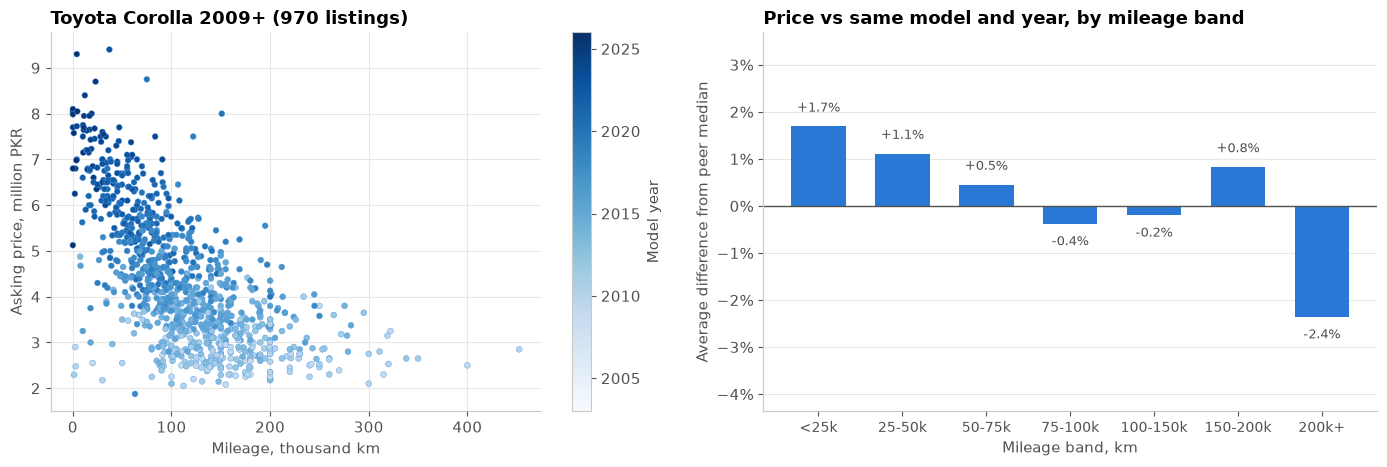

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

corolla = df[(df['model'] == 'Corolla') & df['mileage_km'].notna() & (df['year'] >= 2009)]
sc = axes[0].scatter(corolla['mileage_km'] / 1000, corolla['price_million'], c=corolla['year'], cmap='Blues', vmin=2003, vmax=2026, s=18, edgecolor='#5598e7', linewidth=0.3)
cb = plt.colorbar(sc, ax=axes[0])
cb.set_label('Model year')
axes[0].set_title(f'Toyota Corolla 2009+ ({len(corolla)} listings)')
axes[0].set_xlabel('Mileage, thousand km')
axes[0].set_ylabel('Asking price, million PKR')

pct = (by_km['avg_rel'] - 1) * 100
axes[1].bar(pct.index.astype(str), pct.values, color=blue, width=0.65)
for i, v in enumerate(pct.values):
    axes[1].text(i, v + (0.25 if v >= 0 else -0.25), f'{v:+.1f}%', ha='center', va='bottom' if v >= 0 else 'top', fontsize=9, color='#52514e')
axes[1].axhline(0, color='#52514e', linewidth=1)
axes[1].set_ylim(pct.min() - 2, pct.max() + 2)
axes[1].set_title('Price vs same model and year, by mileage band')
axes[1].set_xlabel('Mileage band, km')
axes[1].set_ylabel('Average difference from peer median')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].grid(axis='x', visible=False)
axes[1].tick_params(axis='x', labelsize=10)
plt.tight_layout()
save('05_mileage')

Once model and year are held fixed, mileage moves the asking price only a little: cars under 25,000 km ask about 2% more than their peers and cars past 200,000 km about 2% less, with nothing much in between. Most of what looks like a mileage effect in the raw scatter is really age. Given how rough the mileage figures are, I would not read more into it than the direction.

## Cities

In [27]:
by_city = df.groupby('city').agg(listings=('price_pkr', 'size'), median_price=('price_million', 'median'), median_year=('year', 'median'),
                                 auto_share=('transmission', lambda s: (s == 'Automatic').mean() * 100),
                                 with_peers=('rel_price', 'count'), avg_rel=('rel_price', geo_mean))
by_city = by_city[by_city['listings'] >= MIN_CITY].sort_values('median_price', ascending=False)
by_city['like_for_like_pct'] = (by_city['avg_rel'] - 1) * 100
print(len(by_city), 'cities with at least', MIN_CITY, 'listings')
by_city.drop(columns='avg_rel')

15 cities with at least 50 listings


,listings,median_price,median_year,auto_share,with_peers,like_for_like_pct
city,,,,,,
Gujranwala,241,3.80,"2,018.00",70.12,195,0.29
Islamabad,1894,3.75,"2,016.00",69.90,1560,4.26
Lahore,2989,3.75,"2,018.00",68.99,2524,-0.44
Sialkot,161,3.69,"2,020.00",68.94,135,-0.67
Karachi,2131,3.65,"2,018.00",74.89,1766,-4.33
Multan,318,3.59,"2,018.50",63.52,278,-0.72
Faisalabad,389,3.48,"2,017.00",63.75,327,-0.87
Peshawar,316,3.35,"2,013.00",74.37,240,5.56
Bahawalpur,61,3.20,"2,017.00",59.02,54,-1.92


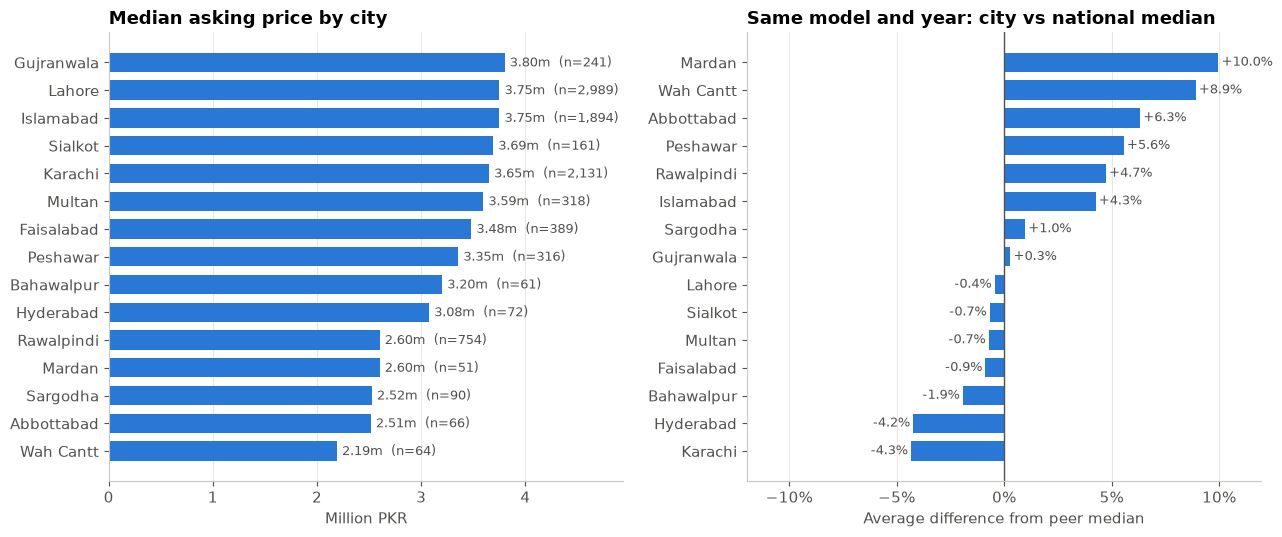

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
d = by_city.sort_values('median_price')
axes[0].barh(d.index, d['median_price'], color=blue, height=0.7)
for y, v, n in zip(d.index, d['median_price'], d['listings']):
    axes[0].text(v + 0.05, y, f'{v:.2f}m  (n={n:,})', va='center', fontsize=9, color='#52514e')
axes[0].set_xlim(0, d['median_price'].max() * 1.3)
axes[0].set_title('Median asking price by city')
axes[0].set_xlabel('Million PKR')

d = by_city.sort_values('like_for_like_pct')
axes[1].barh(d.index, d['like_for_like_pct'], color=blue, height=0.7)
for y, v in zip(d.index, d['like_for_like_pct']):
    axes[1].text(v + (0.15 if v >= 0 else -0.15), y, f'{v:+.1f}%', va='center', ha='left' if v >= 0 else 'right', fontsize=9, color='#52514e')
axes[1].axvline(0, color='#52514e', linewidth=1)
lim = d['like_for_like_pct'].abs().max() + 2
axes[1].set_xlim(-lim, lim)
axes[1].set_title('Same model and year: city vs national median')
axes[1].set_xlabel('Average difference from peer median')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for ax in axes:
    ax.grid(axis='y', visible=False)
plt.tight_layout()
save('06_cities')

The raw medians differ a lot between cities, but that is mostly a difference in what is on sale (newer, more automatic stock in the big three). Comparing like for like, same model and year, the gaps shrink a lot. Lahore, which supplies the most adverts, sits at zero. Karachi and Hyderabad come out about 4% under, Islamabad, Rawalpindi and Peshawar 4 to 6% over. The largest gaps are Mardan (+10%), Wah Cantt (+9%) and Abbottabad (+6%), each resting on only 42 to 56 comparable cars. Raw medians for Gujranwala, Lahore and Islamabad are practically tied at the top.

## Fuel type, transmission and engine size

In [29]:
by_fuel = df.groupby('fuel_type').agg(listings=('price_pkr', 'size'), median_price=('price_million', 'median'), median_year=('year', 'median'),
                                      median_km=('mileage_km', 'median'), auto_share=('transmission', lambda s: (s == 'Automatic').mean() * 100))
by_fuel['share_pct'] = by_fuel['listings'] / len(df) * 100
print(by_fuel.sort_values('listings', ascending=False))
print()
by_trans = df.groupby('transmission').agg(listings=('price_pkr', 'size'), median_price=('price_million', 'median'), median_year=('year', 'median'),
                                          median_cc=('engine_cc', 'median'), like_for_like=('rel_price', geo_mean))
by_trans['share_pct'] = by_trans['listings'] / len(df) * 100
print(by_trans)

           listings  median_price  median_year  median_km  auto_share  share_pct
fuel_type                                                                       
Petrol         9147          3.15     2,016.00  90,000.00       62.40      86.41
Hybrid          837          5.20     2,019.00  83,134.00       99.76       7.91
Diesel          316          9.25     2,016.50  94,005.00       72.78       2.99
PHEV            111         11.80     2,026.00   7,349.50      100.00       1.05
Electric         92          9.18     2,023.00  13,428.50      100.00       0.87
CNG              59          1.05     2,006.00 103,236.00        5.08       0.56
LPG              16          0.61     1,999.50 100,000.00        6.25       0.15
REEV              8         10.45     2,026.00   2,850.00      100.00       0.08

              listings  median_price  median_year  median_cc  like_for_like  share_pct
transmission                                                                          
Automatic      

In [30]:
# automatic vs manual inside the same model and year, where both exist
both = df.groupby(['model', 'year', 'transmission'])['price_pkr'].agg(['median', 'size']).unstack()
both = both[(both[('size', 'Automatic')] >= 3) & (both[('size', 'Manual')] >= 3)]
premium = both[('median', 'Automatic')] / both[('median', 'Manual')] - 1
print('model-year groups with 3+ of each:', len(premium))
print('median automatic premium: %.1f%%' % (premium.median() * 100))
print('groups where automatic asks more: %.0f%%' % ((premium > 0).mean() * 100))

model-year groups with 3+ of each: 107
median automatic premium: 10.6%
groups where automatic asks more: 89%


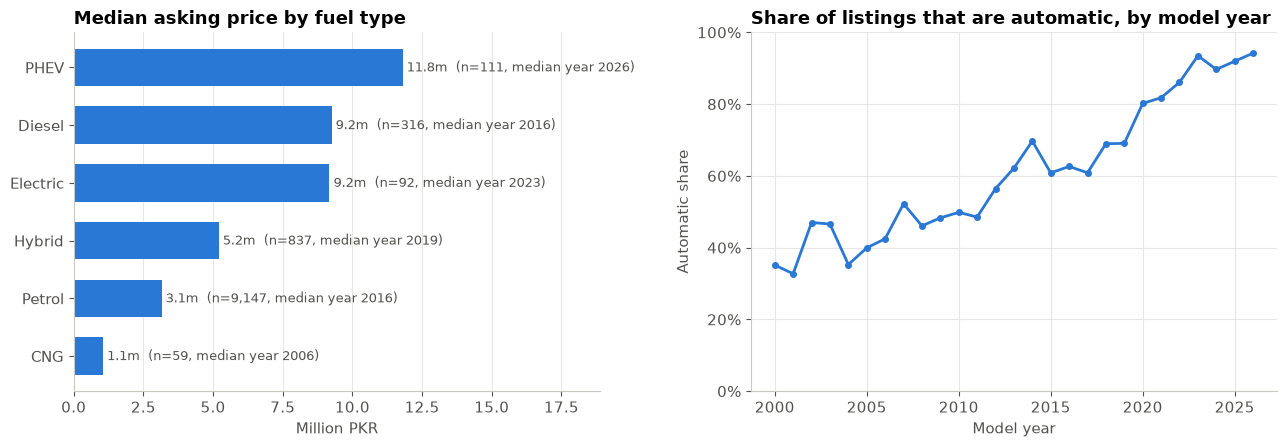

year
2000   35.10
2005   39.90
2010   49.80
2015   60.80
2020   80.20
2023   93.50
2026   94.20
Name: transmission, dtype: float64


In [31]:
auto_by_year = df[df['year'] >= 2000].groupby('year')['transmission'].agg(lambda s: (s == 'Automatic').mean() * 100)
fuel_order = by_fuel[by_fuel['listings'] >= 30].sort_values('median_price').index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
d = by_fuel.loc[fuel_order]
axes[0].barh(d.index, d['median_price'], color=blue, height=0.65)
for y, v, n, yr in zip(d.index, d['median_price'], d['listings'], d['median_year']):
    axes[0].text(v + 0.15, y, f'{v:.1f}m  (n={n:,}, median year {int(yr)})', va='center', fontsize=9, color='#52514e')
axes[0].set_xlim(0, d['median_price'].max() * 1.6)
axes[0].set_title('Median asking price by fuel type')
axes[0].set_xlabel('Million PKR')
axes[0].grid(axis='y', visible=False)

axes[1].plot(auto_by_year.index, auto_by_year.values, color=blue, linewidth=2, marker='o', markersize=4)
axes[1].set_ylim(0, 100)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_title('Share of listings that are automatic, by model year')
axes[1].set_xlabel('Model year')
axes[1].set_ylabel('Automatic share')
plt.tight_layout()
save('07_fuel_and_transmission')
print(auto_by_year.loc[[2000, 2005, 2010, 2015, 2020, 2023, 2026]].round(1))

Plug-in hybrids have the highest median and are nearly all 2026 stock, so that is newness as much as drivetrain. Diesel comes next, which is the Fortuner, Hilux, Prado and Land Cruiser crowd, then electric. CNG and LPG cars are old and cheap. Automatics ask about two and a half times what manuals do overall, but inside the same model and year the premium is around 11%. LPG has too few listings to rank and is left off the chart.

           listings  median_price  p25   p75  median_year
cc_band                                                  
up to 660      1180          2.73 2.27  3.45     2,019.00
661-1000       2640          1.66 0.98  2.75     2,014.00
1001-1300      1914          3.00 2.25  3.95     2,015.00
1301-1600      2201          4.87 3.50  7.00     2,020.00
1601-2000      1640          5.40 3.59  6.80     2,018.00
2001-3000       614         10.45 6.46 15.50     2,018.00
over 3000       289         15.50 7.60 33.50     2,013.00

engine_cc
1,000.00    1873
1,300.00    1620
1,500.00    1549
660.00      1140
1,800.00    1119
1,600.00     560
800.00       529
2,000.00     515
Name: count, dtype: int64


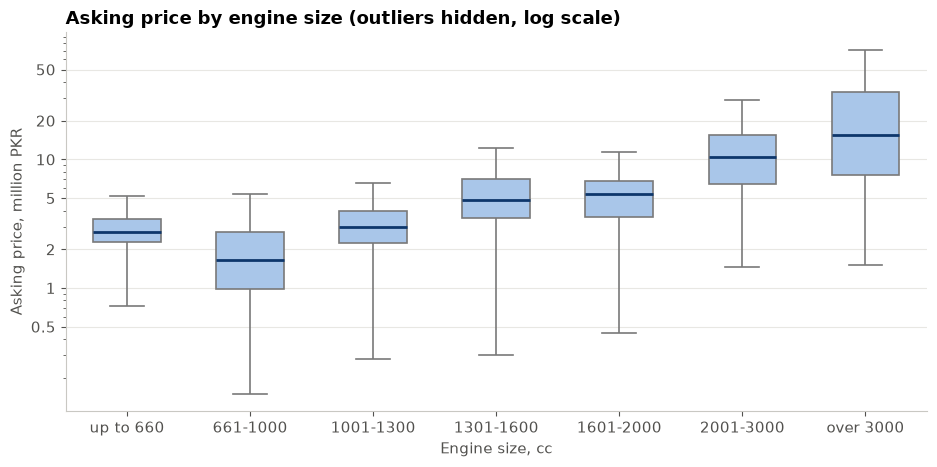

In [32]:
cc_bins = [0, 660, 1000, 1300, 1600, 2000, 3000, 6000]
cc_labels = ['up to 660', '661-1000', '1001-1300', '1301-1600', '1601-2000', '2001-3000', 'over 3000']
df['cc_band'] = pd.cut(df['engine_cc'], cc_bins, labels=cc_labels)
by_cc = df.groupby('cc_band', observed=True).agg(listings=('price_pkr', 'size'), median_price=('price_million', 'median'),
                                                 p25=('price_million', lambda s: s.quantile(.25)), p75=('price_million', lambda s: s.quantile(.75)),
                                                 median_year=('year', 'median'))
print(by_cc)
print()
print(df['engine_cc'].value_counts().head(8))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.boxplot(data=df.dropna(subset=['cc_band']), x='cc_band', y='price_million', color='#9ec5f4', width=0.55, showfliers=False,
            linewidth=1.2, medianprops={'color': '#0d366b', 'linewidth': 2}, ax=ax)
ax.set_yscale('log')
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50])
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter('%g'))
ax.set_title('Asking price by engine size (outliers hidden, log scale)')
ax.set_xlabel('Engine size, cc')
ax.set_ylabel('Asking price, million PKR')
ax.grid(axis='x', visible=False)
plt.tight_layout()
save('08_engine_size')

Price climbs with engine size at every step except one: the 660 cc class asks more than the 661-1000 cc class. The 660s are mostly recent Japanese-import kei cars and newer Altos, while the 800-1000 cc group is full of old Mehrans and Cultus.

## Highest / lowest / most

In [33]:
def show(label, row):
    km = 'n/a' if pd.isna(row['mileage_km']) else f"{row['mileage_km']:,.0f} km"
    print(f"{label}: {row['title'].replace(' for Sale', '')}, {row['city']}, PKR {row['price_pkr']:,.0f}, {km}")

show('Most expensive listing', df.loc[df['price_pkr'].idxmax()])
show('Cheapest listing', df.loc[df['price_pkr'].idxmin()])
show('Oldest model year', df.sort_values(['year', 'listing_id']).iloc[0])
show('Highest believable mileage', df.loc[df['mileage_km'].idxmax()])
show('Largest engine', df.sort_values(['engine_cc', 'price_pkr'], ascending=False).iloc[0])
show('Most expensive electric', df[df['fuel_type'] == 'Electric'].sort_values('price_pkr').iloc[-1])
show('Most expensive manual', df[df['transmission'] == 'Manual'].sort_values('price_pkr').iloc[-1])
print()
print('Listings at 50 million PKR or more:', (df['price_pkr'] >= 50e6).sum(), '| under 1 million:', (df['price_pkr'] < 1e6).sum())
print('Most listed make: %s (%d, %.1f%%)' % (top_brands.index[0], top_brands.iloc[0], top_brands.iloc[0] / len(df) * 100))
bm = by_model.sort_values('listings', ascending=False).iloc[0]
print('Most listed model: %s %s (%d, median %.2fm)' % (bm.name[0], bm.name[1], bm['listings'], bm['median_price']))
print('Most listed city: %s (%d, %.1f%%)' % (top_cities.index[0], top_cities.iloc[0], top_cities.iloc[0] / len(df) * 100))
yr = df['year'].value_counts()
print('Most common model year: %d (%d listings)' % (yr.index[0], yr.iloc[0]))
print('Dearest make (30+ listings): %s, median %.2fm | cheapest: %s, median %.2fm' % (by_make.index[0], by_make['median_price'].iloc[0], by_make.index[-1], by_make['median_price'].iloc[-1]))
hi = by_model.sort_values('median_price').iloc[-1]; lo = by_model.sort_values('median_price').iloc[0]
print('Dearest model (30+ listings): %s %s, median %.2fm | cheapest: %s %s, median %.2fm' % (hi.name[0], hi.name[1], hi['median_price'], lo.name[0], lo.name[1], lo['median_price']))
print('Dearest city (50+ listings): %s, median %.2fm | cheapest: %s, median %.2fm' % (by_city.index[0], by_city['median_price'].iloc[0], by_city.index[-1], by_city['median_price'].iloc[-1]))
print('Automatic share: %.1f%% | petrol share: %.1f%%' % ((df['transmission'] == 'Automatic').mean() * 100, (df['fuel_type'] == 'Petrol').mean() * 100))
print('Model year 2025-2026 listings: %d (%.1f%%), of which under 1,000 km: %d' % ((df['year'] >= 2025).sum(), (df['year'] >= 2025).mean() * 100, ((df['year'] >= 2025) & (df['mileage_km'] < 1000)).sum()))
print('Median listing: PKR %.2fm, model year %d, %s km' % (df['price_million'].median(), df['year'].median(), f"{df['mileage_km'].median():,.0f}"))

Most expensive listing: Lexus LX 2023 LX 600 Ultra Luxury, Islamabad, PKR 108,000,000, 22,080 km
Cheapest listing: Suzuki FX 1984 GA, Islamabad, PKR 150,000, n/a
Oldest model year: Willys M38 1961, Islamabad, PKR 1,600,000, n/a
Highest believable mileage: Toyota Corona 1984, Faisalabad, PKR 1,250,000, 491,000 km
Largest engine: Lexus LX 2021 LX570, Islamabad, PKR 69,000,000, 18,000 km
Most expensive electric: BMW 7 Series 2023 i7 xDrive60 M Sports, Karachi, PKR 62,500,000, 3,400 km
Most expensive manual: Toyota Coaster 2007 29 Seater F/L, Lahore, PKR 14,500,000, n/a

Listings at 50 million PKR or more: 44 | under 1 million: 812
Most listed make: Toyota (3109, 29.4%)
Most listed model: Toyota Corolla (1241, median 3.67m)
Most listed city: Lahore (2989, 28.2%)
Most common model year: 2021 (961 listings)
Dearest make (30+ listings): Tank, median 22.40m | cheapest: Suzuki, median 1.75m
Dearest model (30+ listings): Toyota Land Cruiser, median 28.55m | cheapest: Suzuki Khyber, median 0.50m


## What the listings show

- The file is real scraped data and it is tidy on structure: no duplicate adverts, no duplicate links, consistent make and fuel labels. It is less clean on values. Three prices were off by a factor of ten, and about 200 mileage figures were filler numbers.
- Three makes (Toyota, Suzuki, Honda) are about three quarters of all listings, and three cities (Lahore, Karachi, Islamabad) are about two thirds.
- The typical advert is a car from the late 2010s at around 3.4 million PKR. Prices are very skewed: the top listing is over 100 million.
- Age is the strongest single driver of asking price. For most common models the price steps down by roughly 4 to 9 percent per year of age, and old small Suzukis hold a floor around a million.
- With model and year held fixed, mileage moves the asking price by about 2% either way and the big cities differ by about 4 to 5%, and an automatic asks about 11% more than a manual. The big raw gaps between cities and between automatic and manual are mostly differences in what is being sold.
- Plug-in hybrids and the newer Chinese brands look expensive largely because nearly all of that stock is one or two years old.

## Limitations

- Asking prices, not sale prices. Nothing here says what buyers paid or whether the car sold.
- One day of adverts from one website. No time trend is possible, and sellers on PakWheels are not a sample of all cars in Pakistan.
- "Depreciation" here is a comparison across model years on one day. It mixes generation changes and new-car price changes in with ageing.
- Year, mileage and engine size are typed by sellers. Some years do not match the model, most mileages are rounded, and my rules for blanking mileage are judgement calls.
- No condition, accident history, registration city, import status or seller type, all of which matter for price.
- City rankings cover 15 cities out of 191; most places have a handful of adverts.